In [1]:
#Question 1.)

#1.1.)

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

warnings.filterwarnings("ignore")
nltk.download("stopwords")
nltk.download("wordnet")

df = pd.read_json("C:/Users/mikay/Desktop/University/2026/ITNPA4-34/Project/Datasets/research_abstracts.json")

print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nClass distribution:\n", df["Label"].value_counts())
print("\nDuplicate abstracts:", df.duplicated(subset="Abstract").sum())
df.head()

Shape: (1138, 3)

Column types:
 DOI         object
Abstract    object
Label       object
dtype: object

Missing values:
 DOI         4
Abstract    0
Label       0
dtype: int64

Class distribution:
 Label
classical    900
ai           238
Name: count, dtype: int64

Duplicate abstracts: 13


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mikay\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\mikay\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [2]:
# Remove duplicate abstracts (they would leak between train and test sets)
df = df.drop_duplicates(subset="Abstract").reset_index(drop=True)

# Remove rows with empty abstracts, if any
df = df[df["Abstract"].str.strip() != ""].reset_index(drop=True)

print("Shape after removing duplicates/empties:", df.shape)

Shape after removing duplicates/empties: (1125, 3)


In [3]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()                              # 1. lowercase
    text = re.sub(r"<[^>]+>", " ", text)             # 2. strip HTML/XML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # 3. strip URLs
    text = re.sub(r"\$[^$]*\$", " ", text)           # 4. strip LaTeX maths like $r<10^{-7}$
    text = re.sub(r"[^a-z\s]", " ", text)            # 5. strip digits, punctuation, symbols
    tokens = text.split()                            # 6. tokenise on whitespace
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2] # 7. drop stop words / tiny tokens, lemmatise
    return " ".join(tokens)

df["clean"] = df["Abstract"].apply(clean_text)

# Compare before and after
example = df.loc[0]
print("RAW:\n", example["Abstract"][:300])
print("\nCLEAN:\n", example["clean"][:300])

RAW:
 Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutio

CLEAN:
 forward looking forecasting inflation rate could help central bank government department better use monetary policy stabilize price prevent impact inflation market entity especially low middle income group also help financial institution investor better make investment decision sense forecast inflat


       n_words_raw  n_words_clean
count  1125.000000    1125.000000
mean    171.594667     104.604444
std     103.924594      62.658418
min      16.000000       9.000000
25%     116.000000      71.000000
50%     152.000000      94.000000
75%     201.000000     122.000000
max    2075.000000    1299.000000


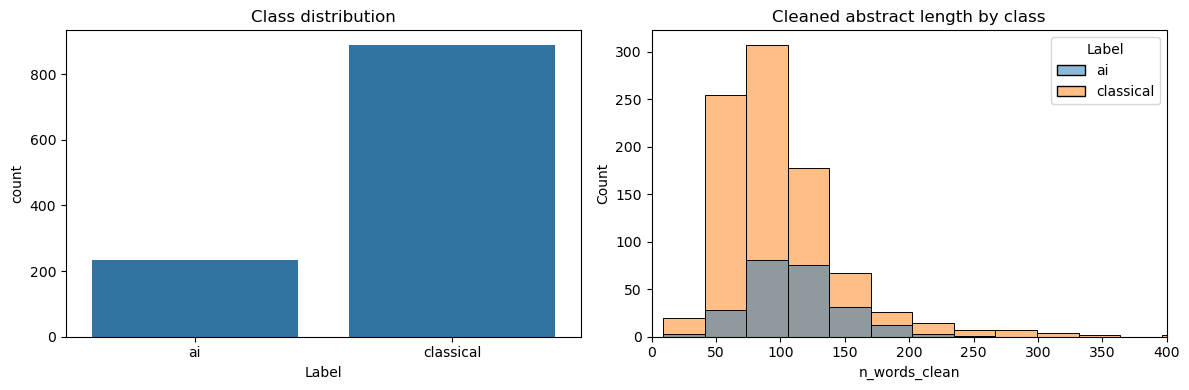

In [4]:
df["n_words_raw"] = df["Abstract"].str.split().str.len()
df["n_words_clean"] = df["clean"].str.split().str.len()

print(df[["n_words_raw", "n_words_clean"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="Label", data=df, ax=ax[0])
ax[0].set_title("Class distribution")
sns.histplot(data=df, x="n_words_clean", hue="Label", bins=40, ax=ax[1])
ax[1].set_xlim(0, 400)
ax[1].set_title("Cleaned abstract length by class")
plt.tight_layout()
plt.show()

In [5]:
#Q1.2.)

# --- Column 1: DOI. Is it an identifier only, or does it leak the label? ---
df["doi_prefix"] = (df["DOI"].fillna("missing")
                    .str.extract(r"^(10\.\d+|https?://[^/]+|missing)")[0])
print("Unique DOIs:", df["DOI"].nunique(), "of", len(df))
print("Unique DOI prefixes:", df["doi_prefix"].nunique())
print(pd.crosstab(df["doi_prefix"], df["Label"])
        .assign(total=lambda x: x.sum(axis=1))
        .sort_values("total", ascending=False).head(6))

# --- Column 2: Abstract length as a candidate numeric feature ---
print(df.groupby("Label")[["n_words_raw", "n_words_clean"]].mean())

Unique DOIs: 1123 of 1125
Unique DOI prefixes: 169
Label       ai  classical  total
doi_prefix                      
10.2139     31        261    292
10.1016     29        168    197
10.1007     22         49     71
10.1080      2         54     56
10.1109     44          9     53
10.1111      3         50     53
           n_words_raw  n_words_clean
Label                                
ai          181.102128     112.438298
classical   169.084270     102.535955


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

y = (df["Label"] == "ai").astype(int)    # 1 = ai, 0 = classical

# Split FIRST so that no information from the test set leaks into feature building
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"], y, test_size=0.2, stratify=y, random_state=42
)

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),   # single words and two-word phrases
    min_df=3,             # ignore terms in fewer than 3 abstracts
    max_df=0.9,           # ignore terms in more than 90% of abstracts
    sublinear_tf=True     # dampen the effect of very frequent words
)
X_train = tfidf.fit_transform(X_train_txt)   # learn vocabulary on training data only
X_test = tfidf.transform(X_test_txt)

print("Train matrix:", X_train.shape)
print("Test matrix :", X_test.shape)

Train matrix: (900, 6585)
Test matrix : (225, 6585)


                  term       chi2   p_value
3875           network  18.416031  0.000018
3341           machine  18.326426  0.000019
3881            neural  17.907222  0.000023
3882    neural network  17.693910  0.000026
3342  machine learning  17.041333  0.000037
3201          learning  15.187088  0.000097
171          algorithm  14.709348  0.000125
3337              lstm   9.955015  0.001604
264                ann   7.903090  0.004935
2253            forest   7.434192  0.006400
4797     random forest   6.983974  0.008224
5885               svr   6.965534  0.008309
353         artificial   6.840340  0.008912
4769          quantile   6.733759  0.009461
2412              gold   6.478753  0.010917


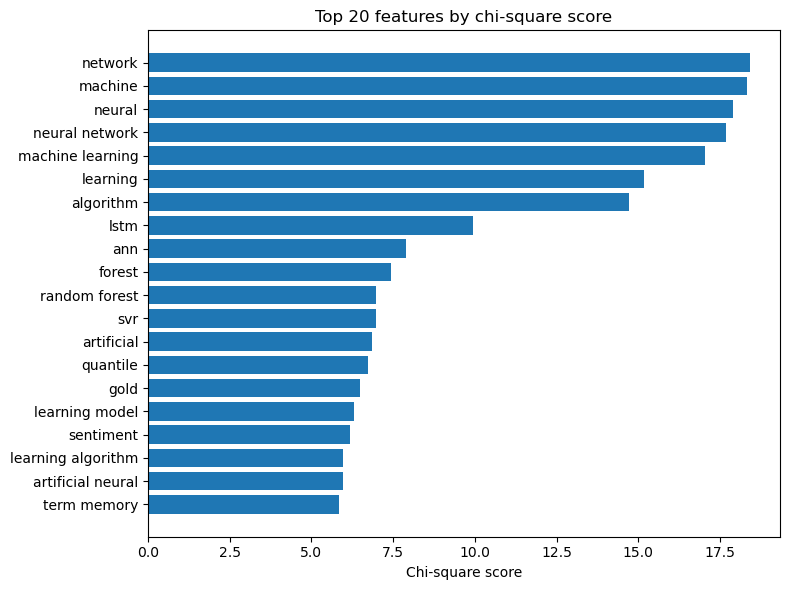

In [7]:
from sklearn.feature_selection import chi2

chi_scores, p_values = chi2(X_train, y_train)
feature_names = np.array(tfidf.get_feature_names_out())

chi_df = (pd.DataFrame({"term": feature_names, "chi2": chi_scores, "p_value": p_values})
            .sort_values("chi2", ascending=False))
print(chi_df.head(15))

top = chi_df.head(20).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["term"], top["chi2"])
plt.title("Top 20 features by chi-square score")
plt.xlabel("Chi-square score")
plt.tight_layout()
plt.show()

In [8]:
#Q1.3.)

from sklearn.linear_model import LogisticRegression

baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
baseline.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

     Set  Accuracy  F1 (ai)  ROC-AUC
0  Train     0.986    0.966    0.999
1   Test     0.867    0.694    0.890

Test set classification report:
              precision    recall  f1-score   support

   classical       0.93      0.90      0.91       178
          ai       0.67      0.72      0.69        47

    accuracy                           0.87       225
   macro avg       0.80      0.81      0.80       225
weighted avg       0.87      0.87      0.87       225



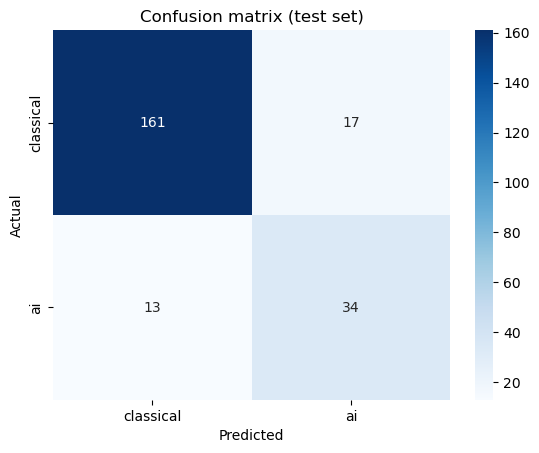

In [9]:
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

def evaluate(name, model, X, y_true):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {"Set": name,
            "Accuracy": accuracy_score(y_true, pred),
            "F1 (ai)": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob)}

results = pd.DataFrame([evaluate("Train", baseline, X_train, y_train),
                        evaluate("Test", baseline, X_test, y_test)]).round(3)
print(results)

print("\nTest set classification report:")
print(classification_report(y_test, baseline.predict(X_test),
                            target_names=["classical", "ai"]))

cm = confusion_matrix(y_test, baseline.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["classical", "ai"], yticklabels=["classical", "ai"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)")
plt.show()

CV F1 per fold: [0.747 0.717 0.75  0.767 0.796]
Mean F1: 0.756  (std 0.026)


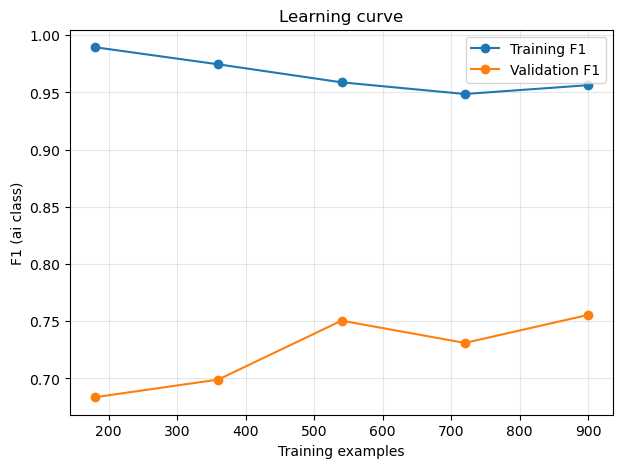

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 5-fold cross-validated F1 for the AI class
scores = cross_val_score(pipe, df["clean"], y, cv=cv, scoring="f1")
print("CV F1 per fold:", scores.round(3))
print(f"Mean F1: {scores.mean():.3f}  (std {scores.std():.3f})")

# Learning curve
sizes, train_sc, val_sc = learning_curve(
    pipe, df["clean"], y, cv=cv, scoring="f1",
    train_sizes=np.linspace(0.2, 1.0, 5), random_state=42)

plt.figure(figsize=(7, 5))
plt.plot(sizes, train_sc.mean(axis=1), "o-", label="Training F1")
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="Validation F1")
plt.xlabel("Training examples"); plt.ylabel("F1 (ai class)")
plt.title("Learning curve"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [11]:
coefs = baseline.coef_[0]
order = np.argsort(coefs)
print("Strongest 'classical' terms:", list(feature_names[order[:10]]))
print("Strongest 'ai' terms       :", list(feature_names[order[::-1][:10]]))

Strongest 'classical' terms: ['policy', 'monetary', 'real', 'interest', 'nominal', 'test', 'interest rate', 'evidence', 'expected', 'cost']
Strongest 'ai' terms       : ['network', 'learning', 'neural', 'neural network', 'machine', 'algorithm', 'machine learning', 'method', 'sentiment', 'quantile']


In [26]:
#QUESTION 2:

#Q2.1.)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)

models = {
    "Logistic Regression (baseline)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=42),
    "Complement Naive Bayes": ComplementNB(),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", model)])
    pipe.fit(X_train_txt, y_train)
    pred = pipe.predict(X_test_txt)

    # LinearSVC has no predict_proba, so use its decision score for ROC-AUC
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_test_txt)[:, 1]
    else:
        score = pipe.decision_function(X_test_txt)

    cv_f1 = cross_val_score(pipe, X_train_txt, y_train, cv=cv,
                            scoring="f1", n_jobs=-1).mean()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (ai)": precision_score(y_test, pred),
        "Recall (ai)": recall_score(y_test, pred),
        "F1 (ai)": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
        "CV F1 (train)": cv_f1,
    })

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
results = pd.DataFrame(rows).set_index("Model").round(3)
results.sort_values("F1 (ai)", ascending=False)

,Accuracy,Precision (ai),Recall (ai),F1 (ai),ROC-AUC,CV F1 (train)
Model,,,,,,
Gradient Boosting,0.898,0.816,0.660,0.729,0.932,0.750
Linear SVM,0.889,0.775,0.660,0.713,0.894,0.823
Logistic Regression (baseline),0.867,0.667,0.723,0.694,0.890,0.773
Random Forest,0.889,0.958,0.489,0.648,0.915,0.704
Complement Naive Bayes,0.880,0.857,0.511,0.640,0.880,0.699


In [28]:
#Q2.2.)

from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict

# Same four models, all needing predict_proba. The SVM is wrapped in a calibrator to get probabilities.
thr_models = {
    "Linear SVM": CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=42), cv=5),
    "Complement Naive Bayes": ComplementNB(),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

thresholds = np.arange(0.05, 0.80, 0.01)
out, final = [], {}

for name, model in thr_models.items():
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", model)])

    # Out-of-fold probabilities on TRAINING data only (no test leakage)
    oof = cross_val_predict(pipe, X_train_txt, y_train, cv=cv,
                            method="predict_proba", n_jobs=-1)[:, 1]
    f1_curve = [f1_score(y_train, oof >= t) for t in thresholds]
    best_t = float(thresholds[int(np.argmax(f1_curve))])

    # Fit on full training set, evaluate on test with default vs tuned threshold
    pipe.fit(X_train_txt, y_train)
    p = pipe.predict_proba(X_test_txt)[:, 1]
    before, after = p >= 0.5, p >= best_t

    out.append({
        "Model": name, "Best threshold": round(best_t, 2),
        "F1 @0.50": f1_score(y_test, before), "F1 @tuned": f1_score(y_test, after),
        "Recall @0.50": recall_score(y_test, before), "Recall @tuned": recall_score(y_test, after),
        "Precision @0.50": precision_score(y_test, before), "Precision @tuned": precision_score(y_test, after),
        "CV F1 @0.50": f1_score(y_train, oof >= 0.5), "CV F1 @tuned": max(f1_curve),
    })
    final[name] = (pipe, best_t)

thr_results = pd.DataFrame(out).set_index("Model").round(3)
thr_results.T

Model,Linear SVM,Complement Naive Bayes,Random Forest,Gradient Boosting
Best threshold,0.470,0.330,0.360,0.540
F1 @0.50,0.713,0.640,0.639,0.729
F1 @tuned,0.725,0.688,0.733,0.714
Recall @0.50,0.660,0.511,0.489,0.660
Recall @tuned,0.702,0.681,0.702,0.638
Precision @0.50,0.775,0.857,0.920,0.816
Precision @tuned,0.750,0.696,0.767,0.811
CV F1 @0.50,0.815,0.700,0.705,0.749
CV F1 @tuned,0.822,0.780,0.816,0.759


In [30]:
#Q2.3.)

import joblib

best_name = thr_results["F1 @tuned"].idxmax()
best_pipe, best_threshold = final[best_name]
print("Best model:", best_name, "| threshold:", round(best_threshold, 2))

joblib.dump({"pipeline": best_pipe, "threshold": best_threshold}, "best_model.joblib")
print("Saved to best_model.joblib")

Best model: Random Forest | threshold: 0.36
Saved to best_model.joblib


In [32]:
app_code = '''
import re
import joblib
import nltk
import streamlit as st
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"\\$[^$]*\\$", " ", text)
    text = re.sub(r"[^a-z\\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split()
              if t not in stop_words and len(t) > 2]
    return " ".join(tokens)

@st.cache_resource
def load_model():
    return joblib.load("best_model.joblib")

bundle = load_model()
pipeline, threshold = bundle["pipeline"], bundle["threshold"]

st.title("Researchly Research Abstract Classifier")
st.write("This app classifies research abstracts as either AI-related or classical research.")

abstract = st.text_area("Enter research abstract:", height=250)

if st.button("Classify Abstract"):
    if not abstract.strip():
        st.warning("Please enter an abstract first.")
    else:
        cleaned = clean_text(abstract)
        prob_ai = pipeline.predict_proba([cleaned])[0, 1]
        st.subheader("Prediction")
        if prob_ai >= threshold:
            st.success("The abstract is classified as: artificial intelligence")
        else:
            st.success("The abstract is classified as: classical research")
        st.caption(f"Model confidence for 'artificial intelligence': {prob_ai:.1%}")
'''

with open("app.py", "w") as f:
    f.write(app_code)
print("app.py written")

app.py written


In [45]:
#So the app runs from either the terminal or Anaconda prompt which is what I used so these are the steps I did to have the streamlit app run:

# Q2.3 Deployment: how to run the web interface

#The Streamlit app is saved as `app.py` and loads the trained model from `best_model.joblib`.
#Streamlit runs a continuous web server, so it is launched from a terminal (Anaconda Prompt), not from the notebook cell.

#1. Open Anaconda Prompt
#2. cd "C:\Users\mikay\ITNPA Project 1" or the file path
#3. streamlit run app.py
#4. Open http://localhost:8501 in a browser